# Data exploration of the CYP data

Exploration of the data prepared by `prepare_data.py`.

We have two prediction tasks: four numerical inhibition-strength outputs (regression), and two yes/no time-dependent-inhibition outputs (classification). We will inspect their training labels, check the splits, and look at the generated molecular inputs.

Validation and test files are read only for molecule identifiers and split information. We do not inspect their labels or train any models here.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

In [4]:
data_dir = Path("data")
if Path.cwd().name == "notebooks":
    data_dir = Path("../data")

with open(data_dir / "manifest.json") as file:
    manifest = json.load(file)

print("Data folder:", data_dir.resolve())
display(pd.Series(manifest["config"], name="Value").to_frame())

assert manifest["config"]["seed"] == 42
assert manifest["config"]["limit"] is None

Data folder: /Users/aryanmirzazadeh/Developer/02456-deep-learning-cyp-project/data


,Value
data_revision,146282d2ce1532f1803679a834a9bec9dac1e482
seed,42
val_fraction,0.15
test_fraction,0.15
limit,None
rdkit,2025.09.6
protocol,atom-jepa-0.3.0


In [6]:
metadata_columns = ["Molecule_Name", "canonical_smiles", "key", "split"]
split_counts = []
metadata_frames = []

for task in ["regression", "classification"]:
    for split in ["train", "val", "test"]:
        path = data_dir / task / f"{split}.csv"
        frame = pd.read_csv(path, usecols=metadata_columns)
        split_counts.append({"task": task, "split": split, "rows": len(frame)})
        frame["task"] = task
        metadata_frames.append(frame)

split_counts = pd.DataFrame(split_counts)
metadata = pd.concat(metadata_frames, ignore_index=True)
split_counts.pivot(index="task", columns="split", values="rows")[["train", "val", "test"]]

split,train,val,test
task,,,
classification,3382,715,723
regression,3415,728,762


## Molecule stays in one split

`canonical_smiles` is the standardized molecule description used by the starter to group equivalent molecules. A molecule may appear in both tasks, but it must not cross between training, validation and test.

The count below should be zero. The assertion stops the notebook if it is not.

In [8]:
splits_per_molecule = metadata.groupby("canonical_smiles")["split"].nunique()
leaking_molecules = splits_per_molecule[splits_per_molecule > 1]

print("Molecules appearing in more than one split:", len(leaking_molecules))
assert len(leaking_molecules) == 0

Molecules appearing in more than one split: 0


## The 2 training tables

`SMILES` describes the molecule's atoms and connections as text.

`Molecule_Name` is its identifier. The laboratory-result columns are the answers we want to predict, not model inputs.

In [10]:
reg_train = pd.read_csv(data_dir / "regression" / "train.csv")
cls_train = pd.read_csv(data_dir / "classification" / "train.csv")

enzymes = ["CYP1A2", "CYP2C9", "CYP2D6", "CYP3A4"]
reg_targets = [f"{enzyme}_pIC50_direct_inhibition" for enzyme in enzymes]
cls_targets = ["CYP2D6_is_TDI", "CYP3A4_is_TDI"]

reg_train[["Molecule_Name", "SMILES"]].head(3)

,Molecule_Name,SMILES
0,OCNT-0010068,O=C(O)C1=CN=CC=C1
1,OCNT-0014841,NCC1=CC=C(S(N)(=O)=O)C=C1
2,OCNT-0018684,CC(C)NCC(O)COC1=C2C=CC=CC2=CC=C1


In [11]:
reg_labels = reg_train.set_index("Molecule_Name")[reg_targets].copy()
reg_labels.columns = enzymes
reg_labels.head(3)

,CYP1A2,CYP2C9,CYP2D6,CYP3A4
Molecule_Name,,,,
OCNT-0010068,NaN,NaN,NaN,2.273187
OCNT-0014841,NaN,NaN,NaN,2.054066
OCNT-0018684,5.783015,2.834837,4.615707,NaN


These are numerical **pIC50** labels: higher values mean stronger measured inhibition. A blank entry (`NaN`) means the table does not provide an answer for that molecule and protein.

The classification table instead contains `1` for a positive result and `0` for a negative result. A missing answer is still `NaN`, not zero.

In [12]:
cls_labels = cls_train.set_index("Molecule_Name")[cls_targets].copy()
cls_labels.columns = ["CYP2D6", "CYP3A4"]
cls_labels.head(3)

,CYP2D6,CYP3A4
Molecule_Name,,
OCNT-0010068,NaN,0.0
OCNT-0014841,NaN,0.0
OCNT-0017486,NaN,0.0


The same molecule can have results in both tables. For example, it may have numerical inhibition measurements and separate yes/no time-dependent-inhibition results. This finds shared identifiers in the training data.

In [13]:
shared_names = set(reg_train["Molecule_Name"]) & set(cls_train["Molecule_Name"])
print("Training molecules appearing in both tasks:", len(shared_names))
reg_train.loc[reg_train["Molecule_Name"].isin(shared_names), ["Molecule_Name", "SMILES"]].head(3)

Training molecules appearing in both tasks: 2496


,Molecule_Name,SMILES
0,OCNT-0010068,O=C(O)C1=CN=CC=C1
1,OCNT-0014841,NCC1=CC=C(S(N)(=O)=O)C=C1
2,OCNT-0018684,CC(C)NCC(O)COC1=C2C=CC=CC2=CC=C1


## Missing answers

In [14]:
reg_coverage = pd.DataFrame(
    {
        "observed": reg_labels.count(),
        "missing": reg_labels.isna().sum(),
    }
)
reg_coverage["missing_percent"] = (100 * reg_labels.isna().mean()).round(1)
reg_coverage

,observed,missing,missing_percent
CYP1A2,973,2442,71.5
CYP2C9,877,2538,74.3
CYP2D6,1041,2374,69.5
CYP3A4,1624,1791,52.4


In [15]:
cls_coverage = pd.DataFrame(
    {
        "observed": cls_labels.count(),
        "missing": cls_labels.isna().sum(),
    }
)
cls_coverage["missing_percent"] = (100 * cls_labels.isna().mean()).round(1)
cls_coverage

,observed,missing,missing_percent
CYP2D6,1045,2337,69.1
CYP3A4,2516,866,25.6


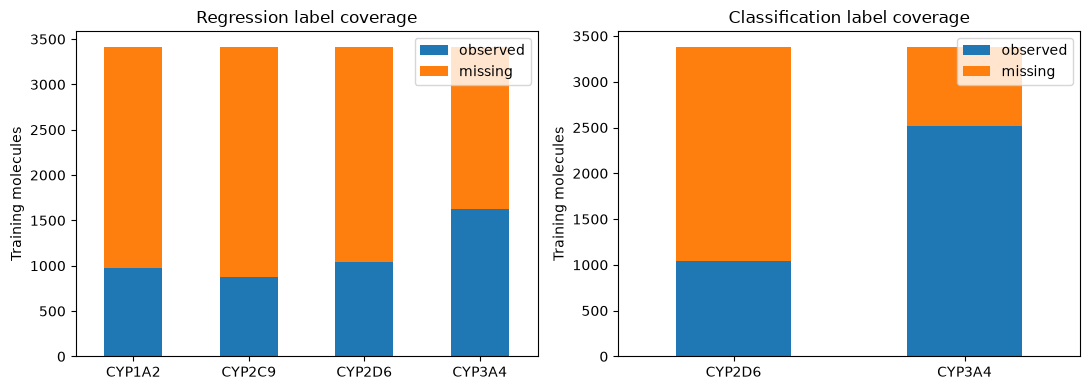

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
reg_coverage[["observed", "missing"]].plot.bar(stacked=True, ax=axes[0], rot=0)
cls_coverage[["observed", "missing"]].plot.bar(stacked=True, ax=axes[1], rot=0)
axes[0].set_title("Regression label coverage")
axes[1].set_title("Classification label coverage")
for ax in axes:
    ax.set_ylabel("Training molecules")
fig.tight_layout()
plt.show()

## Numerical labels

`describe()` summarizes the observed pIC50 values; it skips missing values. The histograms show where those values are concentrated. Their vertical axes count molecules, not model predictions.

In [17]:
reg_labels.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
CYP1A2,973.0,4.99,1.02,1.91,4.62,5.17,5.58,7.95
CYP2C9,877.0,4.57,0.77,2.10,4.14,4.59,5.05,7.38
CYP2D6,1041.0,4.78,0.90,1.95,4.44,4.74,5.28,7.47
CYP3A4,1624.0,4.11,1.08,1.91,3.47,4.27,4.89,7.19


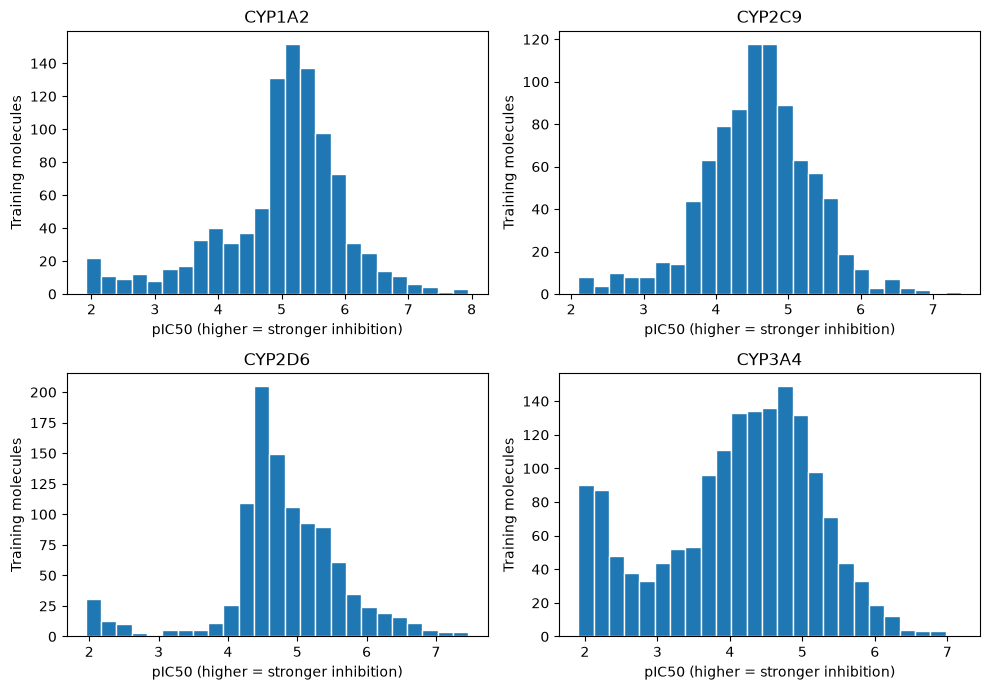

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for enzyme, ax in zip(enzymes, axes.flat):
    ax.hist(reg_labels[enzyme].dropna(), bins=25, edgecolor="white")
    ax.set_title(enzyme)
    ax.set_xlabel("pIC50 (higher = stronger inhibition)")
    ax.set_ylabel("Training molecules")
fig.tight_layout()
plt.show()

The regression CSV also provides uncertainty ranges for the measurements. These are used by the project evaluator, not as input features. Here are a few observed CYP1A2 measurements and their supplied ranges.

In [19]:
target = "CYP1A2_pIC50_direct_inhibition"
intervals = reg_train[[target, target + "_conf_low", target + "_conf_high"]].dropna().head()
intervals.columns = ["pIC50", "lower", "upper"]
intervals

,pIC50,lower,upper
2,5.783015,5.682501,5.880482
5,5.053626,4.950735,5.141120
12,3.864407,3.398772,4.457637
13,1.932732,1.042074,3.173781
20,5.404555,5.297083,5.512080


## Yes/No labels

For each protein, count positive and negative **observed** results. Missing answers are excluded from both counts and from the positive percentage.

This helps us spot class imbalance: an always-negative model can have high accuracy when positive examples are uncommon.

In [20]:
class_balance = pd.DataFrame(
    {
        "negative": (cls_labels == 0).sum(),
        "positive": (cls_labels == 1).sum(),
    }
)
class_balance["positive_percent"] = (100 * class_balance["positive"] / cls_labels.count()).round(1)
class_balance

,negative,positive,positive_percent
CYP2D6,841,204,19.5
CYP3A4,1979,537,21.3


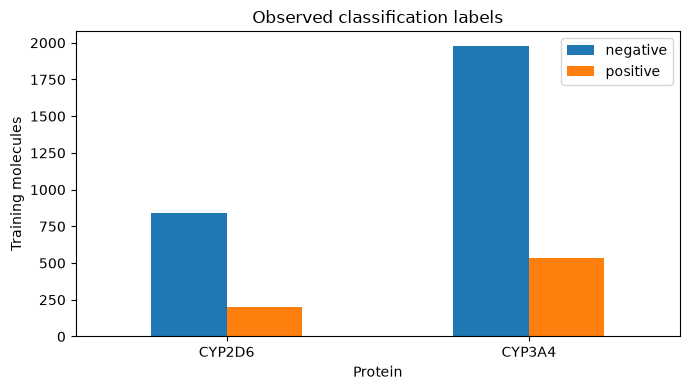

In [21]:
class_balance[["negative", "positive"]].plot.bar(figsize=(7, 4), rot=0)
plt.title("Observed classification labels")
plt.ylabel("Training molecules")
plt.xlabel("Protein")
plt.tight_layout()
plt.show()

## Input molecules

RDKit can turn SMILES into drawings of the atoms and their connections. These are input molecules, not CYP proteins. The drawings below are 2D depictions, not the generated 3D conformers.

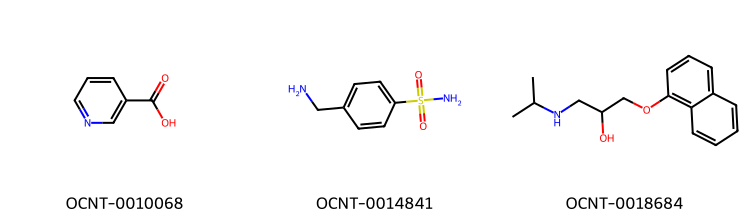

In [23]:
from rdkit import Chem
from rdkit.Chem import Draw

examples = reg_train.head(3)
molecules = [Chem.MolFromSmiles(smiles) for smiles in examples["SMILES"]]
Draw.MolsToGridImage(
    molecules,
    molsPerRow=3,
    subImgSize=(250, 220),
    legends=examples["Molecule_Name"].tolist(),
)

## Conformer preparation

A conformer is one possible 3D arrangement of a molecule's atoms. The report records each generation attempt; an empty error field means success. The excluded file keeps the identifiers of molecules removed after a failure. We only read metadata from that file.

The starter documents two failures caused by impossible stereochemistry: the input descriptions specify incompatible 3D arrangements.

In [25]:
conformer_report = pd.read_csv(data_dir / "conformer_report.csv")
failed = conformer_report[conformer_report["error"].notna()]

print("Successful conformers:", conformer_report["error"].isna().sum())
print("Failed conformers:", len(failed))
assert len(failed) == manifest["failed_conformers"]

excluded = pd.read_csv(
    data_dir / "excluded_conformer_failures.csv",
    usecols=["Molecule_Name", "key"],
)
print(excluded[["Molecule_Name"]])

Successful conformers: 6143
Failed conformers: 2
  Molecule_Name
0  OCNT-0453746
1  OCNT-0453782


Now open the conformer for the first regression training molecule. `key` connects its CSV row to the `.npz` filename.

`z[i]` identifies an atom's element by its atomic number, and `pos[i]` contains that same atom's three coordinates. For example, atomic numbers 1, 6, 7 and 8 mean hydrogen, carbon, nitrogen and oxygen.

In [26]:
example = reg_train.iloc[0]
conformer_path = data_dir / "conformers" / f"{example['key']}.npz"

with np.load(conformer_path) as conformer:
    z = conformer["z"]
    pos = conformer["pos"]

print("Molecule:", example["Molecule_Name"])
print("Atomic numbers shape:", z.shape)
print("Coordinates shape:", pos.shape)
assert pos.shape == (len(z), 3)
assert np.isfinite(pos).all()

pd.DataFrame({"atomic_number": z, "x": pos[:, 0], "y": pos[:, 1], "z": pos[:, 2]}).head()

Molecule: OCNT-0010068
Atomic numbers shape: (14,)
Coordinates shape: (14, 3)


,atomic_number,x,y,z
0,8,-2.129832,1.784710,0.449787
1,6,-1.832266,0.642997,0.151526
2,8,-2.772887,-0.282712,-0.101986
3,6,-0.460456,0.118092,0.026604
4,6,-0.196834,-1.200201,-0.318578


Each dot below is one atom at its stored coordinates. We are not drawing bonds here. The Morgan baseline does not need these coordinates; Atom-JEPA does.

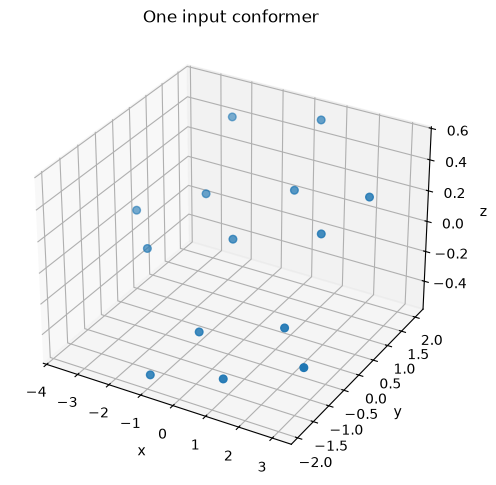

In [27]:
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], s=30)
ax.set_title("One input conformer")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
plt.tight_layout()
plt.show()

## 10. What this means for the next task

- Many molecules have only some labels. Keep the missing-label mask when training.
- The yes/no labels are imbalanced. Accuracy alone will not tell us how well positive cases are recognized.
- The same molecule stays in one split across both tasks. We will reuse these splits for every model.
- The conformer report makes exclusions explicit rather than silently losing rows.

For regression, the required metric is **MA-ST-RAE** (lower is better): it counts prediction errors outside the supplied uncertainty ranges, compares total error with a constant reference, and averages the four proteins' scores. For classification, it is **mean MCC** (higher is better), averaged across the two proteins with probabilities thresholded at 0.5.

These reporting metrics are different from the losses used to train the neural models. No model performance has been measured in this notebook. Part 2 will investigate the Morgan-count fingerprint + MLP baseline, using validation results to choose settings and reserving test results for the final comparison.